# Data drift analysis of the credit scoring API

**Goal:** check whether the clients sent to the deployed API still look like the
clients the model was trained on, and decide what to do if they do not.

**Approach**

1. **Reference:** the 307 511 training clients (60 model features), exported from
   the training notebook (`data/reference.parquet`).
2. **Current data:** the inputs logged by the API in `logs/api_calls.jsonl`
   (one JSON line per call). Production traffic is simulated with
   `simulate_traffic.py`, which sends clients of `application_test` (never seen
   during training):
   - window 1: 2 000 normal calls;
   - window 2: 2 000 calls with a simulated drift (`EXT_SOURCE_2` × 0.7, clients
     5 years younger).
3. **Statistical comparison** with Evidently (`DataDriftPreset`): normalised
   Wasserstein distance for numeric columns, Jensen-Shannon distance for
   categorical ones. A column drifts when its score is at least 0.1; the whole
   dataset drifts when at least 50 % of the columns drift.
4. **Visual comparison** of the key columns, then the effect on the model's
   **decisions** and the **operational** metrics (errors, latency).
5. **Interpretation** and actions.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
from evidently import Report
from evidently.presets import DataDriftPreset

# Works whether the notebook is run from the project root or from notebooks/
ROOT = Path("..") if Path.cwd().name == "notebooks" else Path(".")
WINDOW = 2000

features = (ROOT / "model/features.txt").read_text().splitlines()
reference = pd.read_parquet(ROOT / "data/reference.parquet")
logs = pd.read_json(ROOT / "logs/api_calls.jsonl", lines=True)
logs["window"] = logs.index // WINDOW + 1
successes = logs[logs["status_code"] == 200]

print("Reference:", reference.shape)
print("Logged calls:", len(logs), "| per window:", logs["window"].value_counts().sort_index().to_dict())

Matplotlib is building the font cache; this may take a moment.


Reference: (307511, 60)
Logged calls: 4000 | per window: {1: 2000, 2: 2000}


## 1. Statistical comparison with Evidently

One report per window of 2 000 calls. Only successful calls (status 200) carry
model inputs. The full interactive reports are saved in `reports/`.

In [2]:
def drift_scores(window):
    current = pd.json_normalize(successes[successes["window"] == window]["inputs"]).reindex(columns=features)
    result = Report([DataDriftPreset()]).run(current_data=current, reference_data=reference)
    (ROOT / "reports").mkdir(exist_ok=True)
    result.save_html(str(ROOT / f"reports/data_drift_{window}.html"))
    rows = [
        {"column": m["config"]["column"], "method": m["config"]["method"], "score": round(float(m["value"]), 3)}
        for m in result.dict()["metrics"]
        if m["metric_name"].startswith("ValueDrift")
    ]
    scores = pd.DataFrame(rows).set_index("column")
    scores["drift"] = scores["score"] >= 0.1
    return scores


scores = {window: drift_scores(window) for window in (1, 2)}
summary = pd.DataFrame({
    f"window {w}": {
        "drifted columns": f"{s['drift'].sum()} / {len(s)}",
        "share": f"{s['drift'].mean():.0%}",
        "dataset drift (share >= 50 %)": s["drift"].mean() >= 0.5,
    }
    for w, s in scores.items()
})
summary

,window 1,window 2
drifted columns,8 / 60,10 / 60
share,13%,17%
dataset drift (share >= 50 %),False,False


In [3]:
comparison = pd.DataFrame({"window 1": scores[1]["score"], "window 2": scores[2]["score"]})
comparison["method"] = scores[1]["method"]
drifted = comparison[(comparison["window 1"] >= 0.1) | (comparison["window 2"] >= 0.1)]
drifted.sort_values("window 2", ascending=False)

,window 1,window 2,method
column,,,
EXT_SOURCE_2,0.050,0.806,Wasserstein distance (normed)
PAYMENT_RATE,0.558,0.558,Wasserstein distance (normed)
DAYS_BIRTH,0.061,0.358,Wasserstein distance (normed)
AMT_GOODS_PRICE,0.216,0.216,Wasserstein distance (normed)
AMT_CREDIT,0.214,0.214,Wasserstein distance (normed)
INCOME_CREDIT_PERC,0.207,0.207,Wasserstein distance (normed)
DAYS_LAST_PHONE_CHANGE,0.174,0.174,Wasserstein distance (normed)
NAME_CONTRACT_TYPE,0.152,0.152,Jensen-Shannon distance
AMT_ANNUITY,0.136,0.136,Wasserstein distance (normed)


**Reading:** window 1 already drifts on 8 columns without any simulated
change; window 2 adds exactly the two modified columns, `EXT_SOURCE_2` and
`DAYS_BIRTH`. In both windows, less than 50 % of the columns drift, so Evidently
does **not** flag a drift of the whole dataset.

## 2. Visual comparison of the key columns

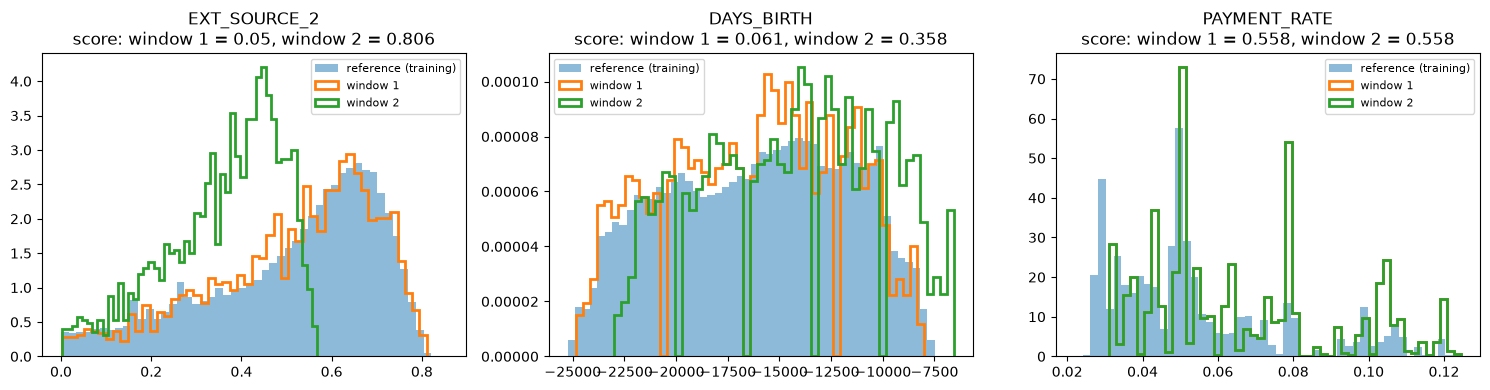

In [4]:
current = {w: pd.json_normalize(successes[successes["window"] == w]["inputs"]) for w in (1, 2)}

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, column in zip(axes, ["EXT_SOURCE_2", "DAYS_BIRTH", "PAYMENT_RATE"]):
    ax.hist(reference[column].dropna(), bins=50, density=True, alpha=0.5, label="reference (training)")
    for w in (1, 2):
        ax.hist(current[w][column].dropna(), bins=50, density=True, histtype="step", linewidth=2, label=f"window {w}")
    ax.set_title(f"{column}\nscore: window 1 = {scores[1].loc[column, 'score']}, window 2 = {scores[2].loc[column, 'score']}")
    ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

In [5]:
contract = pd.DataFrame({
    "reference": reference["NAME_CONTRACT_TYPE"].value_counts(normalize=True),
    "window 1": current[1]["NAME_CONTRACT_TYPE"].value_counts(normalize=True),
    "window 2": current[2]["NAME_CONTRACT_TYPE"].value_counts(normalize=True),
}).round(3)
medians = pd.DataFrame({
    "reference": reference[["AMT_CREDIT", "PAYMENT_RATE"]].median(),
    "window 1": current[1][["AMT_CREDIT", "PAYMENT_RATE"]].median(),
}).round(3)
display(contract)
display(medians)

,reference,window 1,window 2
NAME_CONTRACT_TYPE,,,
Cash loans,0.905,0.992,0.992
Revolving loans,0.095,0.008,0.008


,reference,window 1
AMT_CREDIT,513531.00,450000.000
PAYMENT_RATE,0.05,0.058


**Reading:**

- `EXT_SOURCE_2` and `DAYS_BIRTH`: the window 2 curves are clearly shifted
  (lower external scores, younger clients): this is the simulated drift, and
  Evidently detects it with high scores (0.806 and 0.358).
- `NAME_CONTRACT_TYPE`, `AMT_CREDIT`, `PAYMENT_RATE`: the production clients
  differ from the training clients even without simulation: far fewer revolving
  loans (9.5 % vs about 1 %) and smaller credits, hence a higher `PAYMENT_RATE`
  (annuity / credit). This is a **natural drift** between the two populations.

## 3. Effect on the model's decisions and on operations

In [6]:
per_window = successes.groupby("window").agg(
    calls=("status_code", "size"),
    refusal_rate=("decision", lambda d: round((d == "refused").mean(), 3)),
    mean_probability=("probability_default", lambda p: round(p.mean(), 3)),
    median_latency_ms=("latency_ms", "median"),
)
per_window["error_rate"] = logs.groupby("window")["status_code"].apply(lambda s: round((s != 200).mean(), 4))
per_window

,calls,refusal_rate,mean_probability,median_latency_ms,error_rate
window,,,,,
1,1998,0.261,0.387,3.91,0.001
2,1998,0.342,0.446,3.86,0.001


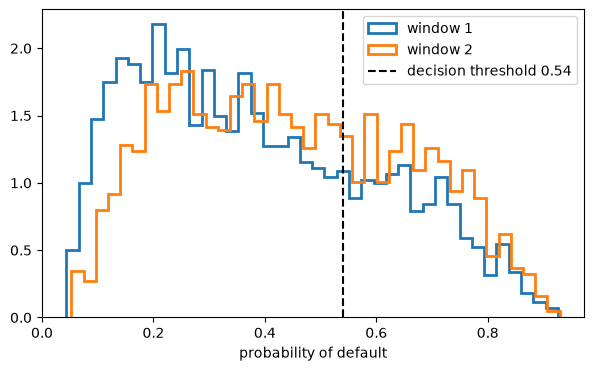

In [7]:
fig, ax = plt.subplots(figsize=(7, 4))
for w in (1, 2):
    ax.hist(successes[successes["window"] == w]["probability_default"], bins=40, density=True, histtype="step", linewidth=2, label=f"window {w}")
ax.axvline(0.54, color="black", linestyle="--", label="decision threshold 0.54")
ax.set_xlabel("probability of default")
ax.legend()
plt.show()

**Reading:** the refusal rate of window 1 (about 26 %) matches the one
expected from the validation set (26.5 %): the natural drift does not change the
decisions much. In window 2, the probabilities shift to the right and the refusal
rate rises to about 34 %: the simulated drift changes about one decision in
twelve, although Evidently does not flag a dataset drift. The error rate stays at
0.1 % (missing `AMT_ANNUITY`, rejected by the API) and the latency does not change.

## 4. Interpretation and actions

**What the results mean**

- The API detects drift where it was simulated: the two modified columns get the
  highest scores of window 2.
- The global flag (at least 50 % of drifted columns) is not a good alarm: it stays
  off while the refusal rate rises from 26 % to 34 %.
- Some drift is natural (different population): 8 columns drift with no
  simulated change. Alerting on every column would create false alarms.

**What to do**

1. **Monitor individually** the most important features (`EXT_SOURCE_*`,
   `PAYMENT_RATE`, `DAYS_BIRTH`) and the **refusal rate**, rather than the global flag.
2. **Use the first weeks of real traffic as a baseline** to separate natural
   drift from new drift.
3. **If a significant drift appears:** check data quality first (a changed
   upstream source or unit, as in window 2), then estimate its business impact
   (refusal rate, cost). Retrain only if the performance drops, which requires
   the true outcomes (defaults), known months later.
4. **Keep the logs** (90 days, pseudonymised) so that the new data can be used
   to retrain the model.